# Module 1 (CO1): Dataset Exploration & Data Understanding
**Project**: Anti-Money Laundering Detection System
**Students**: K. VISHNU (2520030199) & U. VIDHATH (2520030597)
**Guide**: NIRMALAJYOTHI NARISETTY
**Dataset**: IBM Transactions for Anti-Money Laundering (AMLSim) Benchmark (`ibm_aml_transactions.csv`)

In [ ]:
import pandas as pd
import numpy as np

# Load real IBM AML benchmark dataset
df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
print("Dataset Shape:", df.shape)
print("\nAttribute Data Types:\n", df.dtypes)
print("\nFirst 5 Records:")
df.head()

Dataset Shape: (100000, 11)

Attribute Data Types:
 Timestamp                 str
From Bank               int64
Account                   str
To Bank                 int64
Account.1                 str
Amount Received       float64
Receiving Currency        str
Amount Paid           float64
Payment Currency          str
Payment Format            str
Is Laundering           int64
dtype: object

First 5 Records:


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/02 19:08,701,800C62FB0,1853,801CF2040,1688.21,US Dollar,1688.21,US Dollar,Credit Card,0
1,2022/09/07 14:56,12,80C7762B0,32564,80CCDA150,36107.76,Mexican Peso,36107.76,Mexican Peso,Credit Card,0
2,2022/09/04 05:38,24840,8025DD1B0,23691,80312DF90,2963.72,Euro,2963.72,Euro,Cheque,0
3,2022/09/07 01:29,5627,802F88510,18067,803106450,8500.01,Yuan,8500.01,Yuan,Cheque,0
4,2022/09/01 23:02,133452,80C99A850,133686,80C65D1C0,5157.01,Mexican Peso,5157.01,Mexican Peso,Cheque,0


## 2. Dataset Schema & Descriptive Statistics

In [2]:
print("Dataset Information:")
df.info()
print("\nDescriptive Statistics:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Timestamp           100000 non-null  str    
 1   From Bank           100000 non-null  int64  
 2   Account             100000 non-null  str    
 3   To Bank             100000 non-null  int64  
 4   Account.1           100000 non-null  str    
 5   Amount Received     100000 non-null  float64
 6   Receiving Currency  100000 non-null  str    
 7   Amount Paid         100000 non-null  float64
 8   Payment Currency    100000 non-null  str    
 9   Payment Format      100000 non-null  str    
 10  Is Laundering       100000 non-null  int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 8.4 MB

Descriptive Statistics:


,From Bank,To Bank,Amount Received,Amount Paid,Is Laundering
count,100000.000000,100000.000000,1.000000e+05,1.000000e+05,100000.000000
mean,44912.431730,64662.653050,4.193539e+06,4.037346e+06,0.051770
std,80304.593591,83457.553689,3.572458e+08,3.565723e+08,0.221563
min,1.000000,1.000000,1.000000e-06,1.000000e-06,0.000000
25%,118.000000,3655.000000,2.017475e+02,2.030050e+02,0.000000
50%,9665.000000,21381.000000,1.610415e+03,1.613325e+03,0.000000
75%,28255.000000,121698.000000,1.313287e+04,1.310832e+04,0.000000
max,356228.000000,355194.000000,8.485314e+10,8.485314e+10,1.000000


## 3. Banking Network Attributes & Class Balance

In [3]:
print("Unique Sending Banks (From Bank):", df['From Bank'].nunique())
print("Unique Receiving Banks (To Bank):", df['To Bank'].nunique())
print("Unique Originating Accounts:", df['Account'].nunique())
print("Unique Beneficiary Accounts:", df['Account.1'].nunique())
print("\nPayment Format Breakdown:")
print(df['Payment Format'].value_counts())
print("\nReal Target Class Distribution (Is Laundering):")
print(df['Is Laundering'].value_counts())
print(df['Is Laundering'].value_counts(normalize=True).round(4) * 100)

Unique Sending Banks (From Bank): 4845
Unique Receiving Banks (To Bank): 2543
Unique Originating Accounts: 63606
Unique Beneficiary Accounts: 78418

Payment Format Breakdown:
Payment Format
Cheque          35453
Credit Card     24906
ACH             15861
Cash             9451
Reinvestment     8243
Wire             3366
Bitcoin          2720
Name: count, dtype: int64

Real Target Class Distribution (Is Laundering):
Is Laundering
0    94823
1     5177
Name: count, dtype: int64
Is Laundering
0    94.82
1     5.18
Name: proportion, dtype: float64


## 4. Visual Audit: Target Class Distribution & Payment Formats

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_31252\3072748670.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fmt_counts.values, y=fmt_counts.index, ax=axes[1], palette='Blues_r')


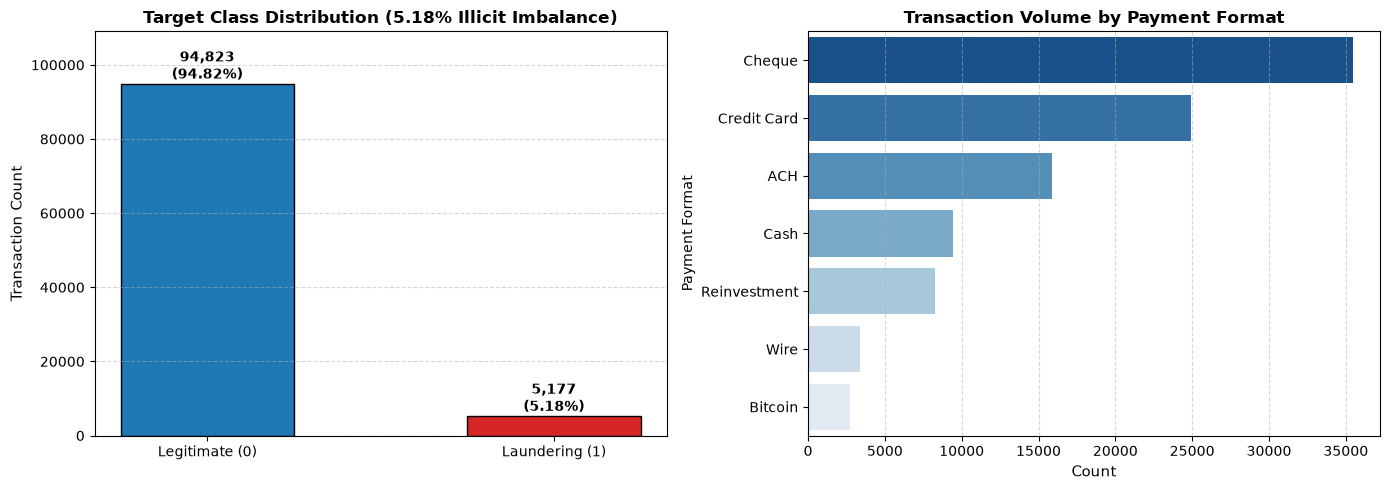

In [4]:
# Visualization: Target Class Distribution & Payment Format Breakdown
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Class Distribution Bar Chart
counts = df['Is Laundering'].value_counts()
pcts = df['Is Laundering'].value_counts(normalize=True) * 100
bars = axes[0].bar(['Legitimate (0)', 'Laundering (1)'], counts.values, 
                   color=['#1f77b4', '#d62728'], width=0.5, edgecolor='black')
axes[0].set_title('Target Class Distribution (5.18% Illicit Imbalance)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Transaction Count', fontsize=11)
axes[0].set_ylim(0, max(counts.values) * 1.15)
for bar, count, pct in zip(bars, counts.values, pcts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1500,
                 f"{count:,}\n({pct:.2f}%)", ha='center', fontsize=10, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Payment Format Breakdown
fmt_counts = df['Payment Format'].value_counts()
sns.barplot(x=fmt_counts.values, y=fmt_counts.index, ax=axes[1], palette='Blues_r')
axes[1].set_title('Transaction Volume by Payment Format', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Count', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
